# Chapter 14: Filtering on Lie groups

This notebook reproduces the examples of the chapter with NumPy, SciPy and Matplotlib only.
The estimate is a point of the group (or of the sphere). Its uncertainty is a vector in a tangent space.

Conventions. A hat marks an estimate. The errors are the estimate relative to the truth,
$E_r = \hat X X^{-1} = \exp(\chi_r^\wedge)$ and $E_\ell = X^{-1}\hat X = \exp(\chi^\wedge)$.
On $\mathrm{SE}_2(3)$ the state is $X = [R\ v\ x]$ and $\chi = (\chi_v, \chi_x, \chi_R)$.
A correction subtracts: $\hat X^+ = \exp(-(\tilde K\tilde y)^\wedge)\,\hat X$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import expm

G = 9.81
E1, E2, E3 = np.eye(3)
np.set_printoptions(precision=4, suppress=True)


def hat(v):
    x, y, z = v
    return np.array([[0.0, -z, y], [z, 0.0, -x], [-y, x, 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    th = np.linalg.norm(w)
    if th < 1e-12:
        return np.eye(3) + hat(w)
    K = hat(w / th)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def unit(v):
    return np.asarray(v, float) / np.linalg.norm(v)


def wrap(a):
    """Wrap an angle into (-pi, pi]: the logarithm on the circle."""
    return np.pi - np.mod(np.pi - a, 2 * np.pi)

## 1. A compass and a gyroscope

A Kalman filter with one state, the heading. The filter that subtracts headings fails when the compass wraps
at $180^\circ$. The filter that takes the innovation on the circle does not.

subtract  largest heading error  179.2 deg, at the end  73.2 deg
wrap      largest heading error    2.0 deg, at the end   1.3 deg


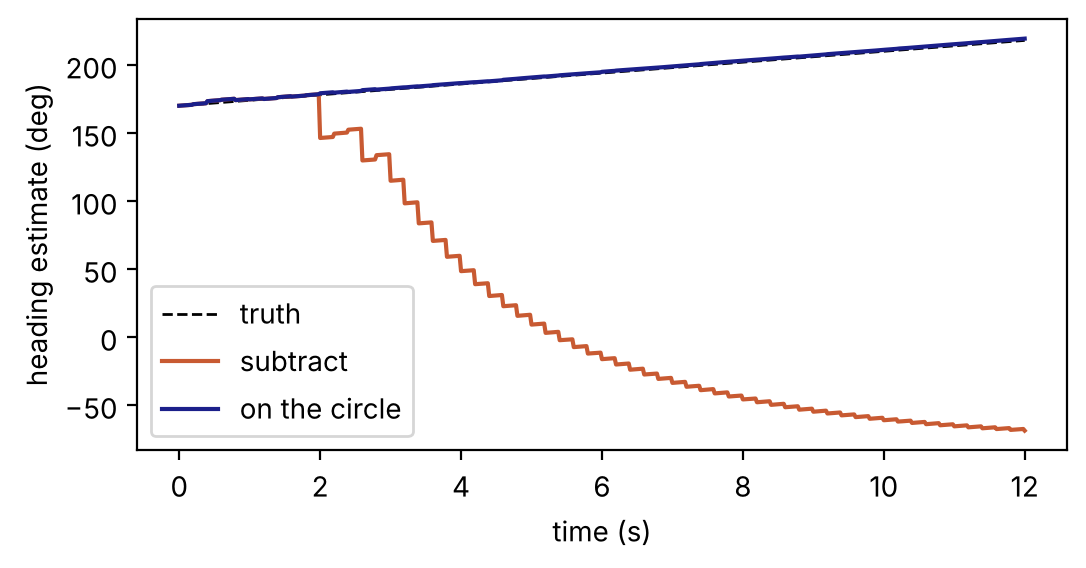

In [2]:
def compass_demo(seed=3, T=12.0, h=0.02, every=10, sig_g=np.radians(0.5), sig_y=np.radians(3.0)):
    """A gyroscope and a compass. Truth crosses the wrap at 180 degrees.

    Returns time, true heading, and the estimates of the filter that subtracts
    and of the filter that takes the logarithm on the circle (wraps).
    """
    rng = np.random.default_rng(seed)
    n = int(round(T / h))
    rate = np.radians(4.0)
    t = np.arange(n + 1) * h
    truth = np.radians(170.0) + rate * t
    est = {"subtract": truth[0], "wrap": truth[0]}
    var = {"subtract": sig_y**2, "wrap": sig_y**2}
    hist = {f: [est[f]] for f in est}
    for k in range(n):
        om = rate + rng.normal() * sig_g
        y = wrap(truth[k + 1] + rng.normal() * sig_y) if (k + 1) % every == 0 else None
        for f in est:
            est[f] += om * h
            var[f] += (sig_g * h) ** 2
            if y is not None:
                innov = est[f] - y if f == "subtract" else wrap(est[f] - y)
                gain = var[f] / (var[f] + sig_y**2)
                est[f] -= gain * innov
                var[f] *= 1 - gain
            hist[f].append(est[f])
    return t, truth, {f: np.array(v) for f, v in hist.items()}


t, truth, hist = compass_demo()
for name, est in hist.items():
    err = np.degrees(np.abs(wrap(est - truth)))
    print(f"{name:9s} largest heading error {err.max():6.1f} deg, at the end {err[-1]:5.1f} deg")
plt.figure(figsize=(6, 2.8))
plt.plot(t, np.degrees(truth), "k--", lw=1, label="truth")
plt.plot(t, np.degrees(hist["subtract"]), color="#c85a32", label="subtract")
plt.plot(t, np.degrees(hist["wrap"]), color="#1b1f8a", label="on the circle")
plt.xlabel("time (s)"); plt.ylabel("heading estimate (deg)"); plt.legend(); plt.show()

## 2. Uncertainty lives in the tangent space

The group helpers, batched over a leading axis, and the banana: 4000 dead-reckoned poses of a planar robot.
With `noisy=False` the initial pose is a concentrated Gaussian and the motion is exact, so
$\chi(t) = \Phi^k\chi(0)$ for every sample and the cloud is exactly Gaussian in exponential coordinates.

In [3]:
def hat_b(w):
    """Hat map on an array (..., 3) -> (..., 3, 3)."""
    w = np.asarray(w, float)
    M = np.zeros(w.shape[:-1] + (3, 3))
    M[..., 0, 1], M[..., 0, 2] = -w[..., 2], w[..., 1]
    M[..., 1, 0], M[..., 1, 2] = w[..., 2], -w[..., 0]
    M[..., 2, 0], M[..., 2, 1] = -w[..., 1], w[..., 0]
    return M


def _coef(w):
    th2 = np.sum(w * w, axis=-1)[..., None, None]
    th = np.sqrt(th2)
    small = th < 1e-5
    ths = np.where(small, 1.0, th)
    a = np.where(small, 1 - th2 / 6, np.sin(ths) / ths)
    b = np.where(small, 0.5 - th2 / 24, (1 - np.cos(ths)) / ths**2)
    c = np.where(small, 1 / 6 - th2 / 120, (ths - np.sin(ths)) / ths**3)
    return a, b, c


def exp_so3_b(w):
    """exp(w^) for an array of rotation vectors (..., 3)."""
    a, b, _ = _coef(w)
    W = hat_b(w)
    return np.eye(3) + a * W + b * W @ W


def jl_b(w):
    """Left Jacobian J(w): exp((w)^ on SE_K(3)) has linear columns J(w_R) w_lin."""
    _, b, c = _coef(w)
    W = hat_b(w)
    return np.eye(3) + b * W + c * W @ W


def log_so3(R):
    """Rotation vector of R (angle in [0, pi])."""
    c = np.clip((np.trace(R) - 1) / 2, -1, 1)
    th = np.arccos(c)
    if th < 1e-7:
        return vee(R - R.T) / 2
    if np.pi - th < 1e-5:
        A = (R + np.eye(3)) / 2
        i = int(np.argmax(np.diag(A)))
        a = A[:, i] / np.sqrt(A[i, i])
        s = vee(R - R.T)
        if s @ a < 0:
            a = -a
        return th * a
    return th / (2 * np.sin(th)) * vee(R - R.T)


def angle_b(R):
    """Rotation angle of each matrix in a batch, in radians."""
    return np.arccos(np.clip((np.trace(R, axis1=-2, axis2=-1) - 1) / 2, -1, 1))


def log_so3_b(R):
    """Rotation vectors of a batch (..., 3, 3). Near half a turn it falls back to log_so3."""
    shape = R.shape[:-2]
    R = R.reshape(-1, 3, 3)
    th = angle_b(R)
    s = np.stack([R[:, 2, 1] - R[:, 1, 2], R[:, 0, 2] - R[:, 2, 0], R[:, 1, 0] - R[:, 0, 1]], -1)
    small = th < 1e-7
    f = np.where(small, 0.5, th / (2 * np.sin(np.where(small, 1.0, th))))
    w = f[:, None] * s
    for i in np.nonzero(np.pi - th < 1e-4)[0]:
        w[i] = log_so3(R[i])
    return w.reshape(shape + (3,))


def sek_mat(R, cols):
    """X = [R c_1 ... c_K; 0 I]."""
    K = len(cols)
    X = np.eye(3 + K)
    X[:3, :3] = R
    for i, c in enumerate(cols):
        X[:3, 3 + i] = c
    return X


def sek_hat(chi):
    """chi = (lin_1, ..., lin_K, rot) -> matrix of the Lie algebra."""
    K = len(chi) // 3 - 1
    M = np.zeros((3 + K, 3 + K))
    M[:3, :3] = hat(chi[3 * K:])
    for i in range(K):
        M[:3, 3 + i] = chi[3 * i:3 * i + 3]
    return M


def sek_vee(M):
    K = M.shape[0] - 3
    return np.concatenate([M[:3, 3 + i] for i in range(K)] + [vee(M[:3, :3])])


def sek_exp(chi):
    K = len(chi) // 3 - 1
    w = chi[3 * K:]
    J = jl_b(w)
    return sek_mat(exp_so3_b(w), [J @ chi[3 * i:3 * i + 3] for i in range(K)])


def sek_log(X):
    K = X.shape[0] - 3
    w = log_so3(X[:3, :3])
    Ji = np.linalg.inv(jl_b(w))
    return np.concatenate([Ji @ X[:3, 3 + i] for i in range(K)] + [w])


def sek_inv(X):
    K = X.shape[0] - 3
    R = X[:3, :3]
    return sek_mat(R.T, [-R.T @ X[:3, 3 + i] for i in range(K)])


def sek_Ad(X):
    """Adjoint matrix: X chi^ X^{-1} = (Ad_X chi)^, in the ordering (lin..., rot)."""
    K = X.shape[0] - 3
    R = X[:3, :3]
    A = np.zeros((3 * K + 3, 3 * K + 3))
    for i in range(K + 1):
        A[3 * i:3 * i + 3, 3 * i:3 * i + 3] = R
    for i in range(K):
        A[3 * i:3 * i + 3, 3 * K:] = hat(X[:3, 3 + i]) @ R
    return A


def Ad_b(R, cols):
    """Batched adjoint of SE_K(3) from R (N,3,3) and a list of K columns (N,3)."""
    K = len(cols)
    N = R.shape[0]
    A = np.zeros((N, 3 * K + 3, 3 * K + 3))
    for i in range(K + 1):
        A[:, 3 * i:3 * i + 3, 3 * i:3 * i + 3] = R
    for i, c in enumerate(cols):
        A[:, 3 * i:3 * i + 3, 3 * K:] = hat_b(c) @ R
    return A

largest |chi - Phi^k chi_0| over the samples: 4.979350265443827e-14
skewness of the forward position: -2.32
skewness of the components of chi: [-0.025, 0.028, 0.028]


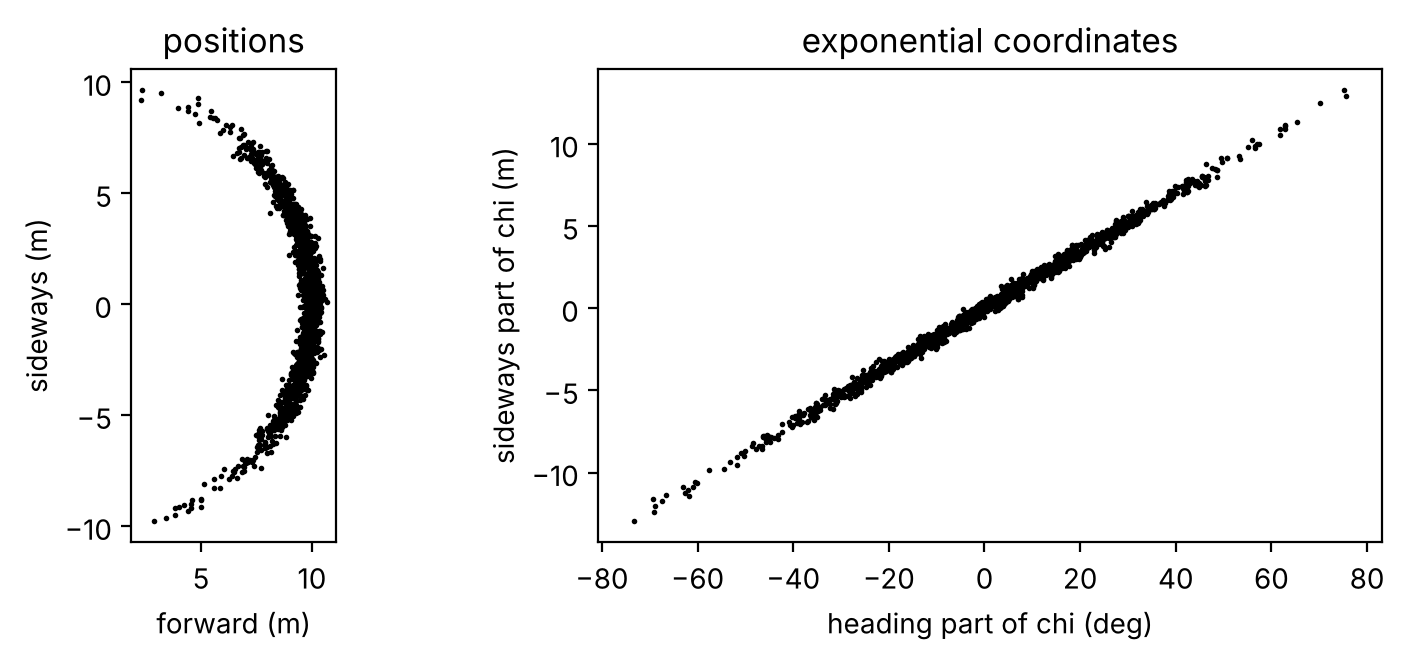

In [4]:
def se2_exp(z):
    """exp of z = (V1, V2, Om) (N, 3) as (theta, x, y) increments in the body frame."""
    th = z[:, 2]
    small = np.abs(th) < 1e-9
    ths = np.where(small, 1.0, th)
    a = np.where(small, 1 - th**2 / 6, np.sin(ths) / ths)
    b = np.where(small, th / 2, (1 - np.cos(ths)) / ths)
    return th, a * z[:, 0] - b * z[:, 1], b * z[:, 0] + a * z[:, 1]


def se2_log(th, x, y):
    th = wrap(th)
    small = np.abs(th) < 1e-9
    ths = np.where(small, 1.0, th)
    a = np.where(small, 1 - th**2 / 6, np.sin(ths) / ths)
    b = np.where(small, th / 2, (1 - np.cos(ths)) / ths)
    det = a * a + b * b
    return np.stack([(a * x + b * y) / det, (-b * x + a * y) / det, th], -1)


def se2_mul(p1, p2):
    th1, x1, y1 = p1
    th2, x2, y2 = p2
    c, s = np.cos(th1), np.sin(th1)
    return th1 + th2, x1 + c * x2 - s * y2, y1 + s * x2 + c * y2


def se2_inv(p):
    th, x, y = p
    c, s = np.cos(th), np.sin(th)
    return -th, -(c * x + s * y), -(-s * x + c * y)


def se2_Ad(th, x, y):
    """Adjoint on (V1, V2, Om) of the pose (th, x, y)."""
    c, s = np.cos(th), np.sin(th)
    return np.array([[c, -s, y], [s, c, -x], [0, 0, 1.0]])


def banana(N=4000, seed=5, T=10.0, h=0.1, speed=1.0, turn=0.0,
           sig_V=0.05, sig_Om=0.12, sig0=(0.0, 0.0, 0.0), noisy=True):
    """Dead reckoning of a planar robot: X_{k+1} = X_k exp((zeta + n_k) h).

    Returns the sample poses at every step, the noise-free pose, the logarithm
    chi = log(Xbar^{-1} X) of every sample and the covariance propagated by the
    linear equation of the left-invariant error.
    """
    rng = np.random.default_rng(seed)
    n = int(round(T / h))
    zeta = np.array([speed, 0.0, turn])
    chi0 = rng.normal(size=(N, 3)) * np.asarray(sig0)
    X = se2_exp(chi0)
    Xbar = (np.zeros(1), np.zeros(1), np.zeros(1))
    Sigma = np.diag(np.asarray(sig0, float) ** 2)
    Sigma_n = np.diag([sig_V**2, (0.2 * sig_V) ** 2, sig_Om**2]) * h if noisy else np.zeros((3, 3))
    step_bar = se2_exp(zeta[None] * h)
    Phi = se2_Ad(*[c[0] for c in se2_inv(step_bar)])        # Ad of exp(-zeta h)
    poses, chis, covs, bars = [], [], [], []
    for k in range(n + 1):
        poses.append(np.stack(X, -1))
        bars.append(np.array([c[0] for c in Xbar]))
        chis.append(se2_log(*se2_mul(se2_inv(Xbar), X)))
        covs.append(Sigma.copy())
        if k == n:
            break
        noise = rng.multivariate_normal(np.zeros(3), Sigma_n / h**2, size=N) if noisy else np.zeros((N, 3))
        X = se2_mul(X, se2_exp((zeta[None] + noise) * h))
        Xbar = se2_mul(Xbar, step_bar)
        Sigma = Phi @ Sigma @ Phi.T + Sigma_n
    return dict(poses=np.array(poses), bar=np.array(bars), chi=np.array(chis), cov=np.array(covs),
                h=h, Phi=Phi)


def skewness(x):
    x = x - x.mean()
    return float(np.mean(x**3) / np.mean(x**2) ** 1.5)


b = banana(noisy=False, sig0=(0.25, 0.25, 0.4))
P, chi = b["poses"][-1], b["chi"][-1]
n = b["chi"].shape[0] - 1
print("largest |chi - Phi^k chi_0| over the samples:",
      np.abs(chi - b["chi"][0] @ np.linalg.matrix_power(b["Phi"], n).T).max())
print("skewness of the forward position:", round(skewness(P[:, 1]), 2))
print("skewness of the components of chi:", [round(skewness(chi[:, i]), 3) for i in range(3)])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
ax[0].plot(P[:1500, 1], P[:1500, 2], "k.", ms=2); ax[0].set_aspect("equal")
ax[0].set_xlabel("forward (m)"); ax[0].set_ylabel("sideways (m)"); ax[0].set_title("positions")
ax[1].plot(np.degrees(chi[:1500, 2]), chi[:1500, 1], "k.", ms=2)
ax[1].set_xlabel("heading part of chi (deg)"); ax[1].set_ylabel("sideways part of chi (m)")
ax[1].set_title("exponential coordinates"); plt.tight_layout(); plt.show()

## 3. An error that does not care where you are

IMU kinematics on $\mathrm{SE}_2(3)$: $\dot R = R\,\Omega^\wedge$, $\dot v = R\,a_s - g\,e_3$, $\dot x = v$.
The same initial error, of 2 rad, is applied to two different flights. The right-invariant errors agree,
and equal $\exp\big((\exp(At)\chi_r(0))^\wedge\big)$ with the constant matrix $A$ of the chapter.

In [5]:
def imu_f(X, Om, a_s):
    """Continuous dynamics f_u(X) of [R v x]: R' = R Om^, v' = R a_s - g e3, x' = v."""
    R, v = X[:3, :3], X[:3, 3]
    F = np.zeros((5, 5))
    F[:3, :3] = R @ hat(Om)
    F[:3, 3] = R @ a_s - G * E3
    F[:3, 4] = v
    return F


def imu_step(R, v, x, Om, a_s, h):
    """One step with the inputs held: batched over the leading axis."""
    acc = np.einsum("...ij,...j->...i", R, a_s) - G * E3
    return R @ exp_so3_b(Om * h), v + acc * h, x + v * h + 0.5 * acc * h * h


def A_right(K=2):
    """Matrix of the log of the right-invariant error of IMU kinematics, order (v, x, [c], R)."""
    n = 3 * K + 3
    A = np.zeros((n, n))
    A[0:3, 3 * K:] = -G * hat(E3)      # chi_v' = -g e3 x chi_R
    A[3:6, 0:3] = np.eye(3)            # chi_x' = chi_v
    return A


def A_left(Om, a_s):
    """Matrix of the log of the left-invariant error: depends on the inputs, not on the state."""
    A = np.zeros((9, 9))
    for i in range(3):
        A[3 * i:3 * i + 3, 3 * i:3 * i + 3] = -hat(Om)
    A[0:3, 6:9] = -hat(a_s)
    A[3:6, 0:3] = np.eye(3)
    return A


def Phi_right(h, K=2):
    A = A_right(K)
    return np.eye(A.shape[0]) + A * h + A @ A * (h * h / 2)     # A^3 = 0


class Scenario:
    """A vehicle flying a banked figure with an IMU, seeing known landmarks in its body frame."""

    def __init__(self, T=20.0, h=0.01, every=10,
                 sig_g=0.01, sig_a=0.1, sig_y=0.1):
        self.h, self.T, self.every = h, T, every
        self.n = int(round(T / h))
        self.sig_g, self.sig_a, self.sig_y = sig_g, sig_a, sig_y
        self.landmarks = np.array([[3.5, 0.5, 0.0], [-2.5, 3.0, 0.0], [-1.5, -3.5, 0.8]])
        t = np.arange(self.n + 1) * h
        w1 = 2 * np.pi / 10.0
        pos = np.stack([2.5 * np.cos(w1 * t), 2.0 * np.sin(w1 * t), 1.5 + 0.5 * np.sin(2 * w1 * t)], -1)
        vel = np.stack([-2.5 * w1 * np.sin(w1 * t), 2.0 * w1 * np.cos(w1 * t), w1 * np.cos(2 * w1 * t)], -1)
        acc = np.stack([-2.5 * w1**2 * np.cos(w1 * t), -2.0 * w1**2 * np.sin(w1 * t),
                        -2 * w1**2 * np.sin(2 * w1 * t)], -1)
        Rs = np.zeros((self.n + 1, 3, 3))
        for k in range(self.n + 1):
            b3 = unit(acc[k] + G * E3)                 # thrust axis of a multicopter
            hd = np.array([vel[k, 0], vel[k, 1], 0.0])
            b2 = unit(np.cross(b3, hd))
            Rs[k] = np.column_stack([np.cross(b2, b3), b2, b3])
        self.Om = np.array([log_so3(Rs[k].T @ Rs[k + 1]) / h for k in range(self.n)])
        self.a_s = np.einsum("kji,kj->ki", Rs[:-1], acc[:-1] + G * E3)
        # the truth is the discrete model driven by these inputs
        R, v, x = Rs[0], vel[0], pos[0]
        self.R, self.v, self.x = [R], [v], [x]
        for k in range(self.n):
            R, v, x = imu_step(R, v, x, self.Om[k], self.a_s[k], h)
            self.R.append(R), self.v.append(v), self.x.append(x)
        self.R, self.v, self.x = np.array(self.R), np.array(self.v), np.array(self.x)
        self.t = t

    def meas(self, k):
        """Noise-free landmark positions in the body frame at step k, shape (L, 3)."""
        return (self.landmarks - self.x[k]) @ self.R[k]


def two_trajectories(T=3.0, h=0.01):
    """The same initial error on two different flights: an aggressive figure and a hover."""
    sc = Scenario(T=T, h=h)
    n = sc.n
    chi0 = np.concatenate([[0.8, -0.5, 0.3], [1.0, 0.5, -0.5], 2.0 * unit([1.0, 2.0, -1.0])])
    E0 = sek_exp(chi0)
    flights = {
        "figure": (sc.R[0], sc.v[0], sc.x[0], sc.Om, sc.a_s),
        "hover": (expm_so3(1.0 * E3), np.zeros(3), np.array([5.0, -2.0, 3.0]),
                  np.zeros((n, 3)), np.tile(G * E3, (n, 1))),
    }
    Phi = Phi_right(h)
    out = {"t": np.arange(n + 1) * h, "chi0": chi0}
    for name, (R, v, x, Om, a_s) in flights.items():
        Xh = E0 @ sek_mat(R, [v, x])
        Rh, vh, xh = Xh[:3, :3], Xh[:3, 3], Xh[:3, 4]
        # the conventional error (dv, dx, dtheta) and its linearized prediction
        d = np.concatenate([vh - v, xh - x, log_so3(R.T @ Rh)])
        Er, add_v, lin_v, chi_lin = [], [], [], []
        chi = chi0.copy()
        for k in range(n + 1):
            Er.append(sek_mat(Rh, [vh, xh]) @ sek_inv(sek_mat(R, [v, x])))
            add_v.append(vh - v)
            lin_v.append(d[0:3].copy())
            chi_lin.append(chi.copy())
            if k == n:
                break
            F = np.eye(9)
            Ra = -Rh @ hat(a_s[k])
            F[0:3, 6:9] = Ra * h
            F[3:6, 0:3] = np.eye(3) * h
            F[3:6, 6:9] = Ra * (h * h / 2)
            F[6:9, 6:9] = expm_so3(-Om[k] * h)
            d = F @ d
            chi = Phi @ chi
            R, v, x = imu_step(R, v, x, Om[k], a_s[k], h)
            Rh, vh, xh = imu_step(Rh, vh, xh, Om[k], a_s[k], h)
        out[name] = dict(Er=np.array(Er), add_v=np.array(add_v), lin_v=np.array(lin_v), chi=np.array(chi_lin))
    return out


two = two_trajectories()
gap = np.abs(two["figure"]["Er"] - two["hover"]["Er"]).max()
ll = max(np.abs(two[f]["Er"][k] - sek_exp(two[f]["chi"][k])).max() for f in ("figure", "hover") for k in range(0, 301, 10))
print("right-invariant errors of the two flights differ by", gap)
print("E_r(t) - exp((Phi^k chi_0)^):", ll)
k = 200
print("additive velocity errors after 2 s differ by",
      round(np.linalg.norm(two["figure"]["add_v"][k] - two["hover"]["add_v"][k]), 2), "m/s")

# the group-affine property, checked at random points
rng = np.random.default_rng(0)
X1, X2 = sek_exp(rng.normal(size=9)), sek_exp(rng.normal(size=9))
Om, a_s = rng.normal(size=3), rng.normal(size=3)
f = lambda Z: imu_f(Z, Om, a_s)
print("group-affine residual:", np.abs(f(X1 @ X2) - (f(X1) @ X2 + X1 @ f(X2) - X1 @ f(np.eye(5)) @ X2)).max())

right-invariant errors of the two flights differ by 3.268496584496461e-13
E_r(t) - exp((Phi^k chi_0)^): 5.044853423896711e-13
additive velocity errors after 2 s differ by 2.74 m/s
group-affine residual: 4.440892098500626e-16


## 4. The invariant extended Kalman filter

`run_filters` runs the right-invariant filter and the conventional error-state filter side by side on
identical readings, batched over Monte Carlo runs.

Propagation: $\Sigma_{k+1} = \exp(Ah)\,(\Sigma_k + \mathrm{Ad}_{\hat X_k}\Sigma_n\mathrm{Ad}_{\hat X_k}^\top)\exp(Ah)^\top$.
Innovation for a landmark at $x_m$: $\tilde y = \hat R\,y + \hat x - x_m$, with $C_y = [\,0\ \ I\ \ -x_m^\wedge\,]$.
Gain: $\tilde K = \Sigma C_y^\top(C_y\Sigma C_y^\top + \hat R\Sigma_y\hat R^\top)^{-1}$.
Correction: $\hat X^+ = \exp(-(\tilde K\tilde y)^\wedge)\,\hat X$.

In [6]:
def initial_estimates(sc, rng, N, ang_deg, sig_v, sig_x, fixed_angle=False):
    """Estimates at k = 0: Rhat = R exp(dtheta^), vhat = v + dv, xhat = x + dx."""
    if fixed_angle:
        dth = np.radians(ang_deg) * np.array([unit(a) for a in rng.normal(size=(N, 3))])
    else:
        dth = rng.normal(size=(N, 3)) * np.radians(ang_deg)
    R = sc.R[0] @ exp_so3_b(dth)
    v = sc.v[0] + rng.normal(size=(N, 3)) * sig_v
    x = sc.x[0] + rng.normal(size=(N, 3)) * sig_x
    return R, v, x


def sigma0_std(N, ang_deg, sig_v, sig_x):
    d = np.concatenate([np.full(3, sig_v**2), np.full(3, sig_x**2), np.full(3, np.radians(ang_deg)**2)])
    return np.tile(np.diag(d), (N, 1, 1))


def run_filters(sc, rng, N, ang_deg, sig_v, sig_x, which=("inv", "std"), fixed_angle=False,
                cov_deg=None, keep=False, side="left"):
    """Monte Carlo of the right-invariant and the conventional extended Kalman filter on one scenario.

    Both filters get the same initial estimate, the same initial covariance (written in
    each filter's own error coordinates) and the same noisy readings.
    Returns, per filter, arrays over (step, run): attitude error [rad], position error,
    velocity error, and the normalized estimation error squared (NEES).
    """
    h = sc.h
    R0, v0, x0 = initial_estimates(sc, rng, N, ang_deg, sig_v, sig_x, fixed_angle)
    S0 = sigma0_std(N, cov_deg or ang_deg, sig_v, sig_x)
    Sigma_n = np.zeros((9, 9))
    Sigma_n[0:3, 0:3] = np.eye(3) * (sc.sig_a * h) ** 2
    Sigma_n[6:9, 6:9] = np.eye(3) * (sc.sig_g * h) ** 2
    Sigma_y = np.eye(3 * len(sc.landmarks)) * sc.sig_y**2
    Phi = Phi_right(h)
    Cy = np.concatenate([np.hstack([np.zeros((3, 3)), np.eye(3), -hat(x_m)]) for x_m in sc.landmarks])
    I9 = np.eye(9)
    st = {}
    if "inv" in which:
        T0 = Ad_b(R0, [v0, x0])                      # chi = T delta at the estimate
        T0[:, 0:3, 0:3] = np.eye(3)
        T0[:, 3:6, 3:6] = np.eye(3)
        st["inv"] = [R0.copy(), v0.copy(), x0.copy(), T0 @ S0 @ np.swapaxes(T0, 1, 2)]
    if "std" in which:
        st["std"] = [R0.copy(), v0.copy(), x0.copy(), S0.copy()]
    out = {f: dict(att=[], pos=[], vel=[], nees=[]) for f in st}
    hist = {f: [] for f in st} if keep else None
    gn = rng.normal(size=(sc.n, N, 3)) * sc.sig_g
    an = rng.normal(size=(sc.n, N, 3)) * sc.sig_a
    L = len(sc.landmarks)

    def log_state(k):
        Rt, vt, xt = sc.R[k], sc.v[k], sc.x[k]
        for f, (R, v, x, Sigma) in st.items():
            ER = R @ Rt.T
            out[f]["att"].append(angle_b(ER))
            out[f]["pos"].append(np.linalg.norm(x - xt, axis=1))
            out[f]["vel"].append(np.linalg.norm(v - vt, axis=1))
            if f == "inv":
                w = log_so3_b(ER)
                Ji = np.linalg.inv(jl_b(w))
                e = np.concatenate([np.einsum("nij,nj->ni", Ji, v - ER @ vt),
                                    np.einsum("nij,nj->ni", Ji, x - ER @ xt), w], axis=1)
            else:
                e = np.concatenate([v - vt, x - xt, log_so3_b(Rt.T @ R)], axis=1)
            out[f]["nees"].append(np.einsum("ni,ni->n", e, np.linalg.solve(Sigma, e[..., None])[..., 0]) / 9)
            if keep:
                hist[f].append((R.copy(), v.copy(), x.copy(), Sigma.copy()))

    log_state(0)
    for k in range(sc.n):
        Om = sc.Om[k] + gn[k]
        a_s = sc.a_s[k] + an[k]
        if "inv" in st:
            R, v, x, Sigma = st["inv"]
            Ad = Ad_b(R, [v, x])
            Sigma = Phi @ (Sigma + Ad @ Sigma_n @ np.swapaxes(Ad, 1, 2)) @ Phi.T
            R, v, x = imu_step(R, v, x, Om, a_s, h)
            st["inv"] = [R, v, x, Sigma]
        if "std" in st:
            R, v, x, Sigma = st["std"]
            F = np.tile(I9, (N, 1, 1))
            Ra = -R @ hat_b(a_s)
            F[:, 0:3, 6:9] = Ra * h
            F[:, 3:6, 0:3] = np.eye(3) * h
            F[:, 3:6, 6:9] = Ra * (h * h / 2)
            F[:, 6:9, 6:9] = exp_so3_b(-Om * h)
            Gn = np.zeros((N, 9, 9))
            Gn[:, 0:3, 0:3] = R
            Gn[:, 6:9, 6:9] = np.eye(3)
            Sigma = F @ (Sigma + Gn @ Sigma_n @ np.swapaxes(Gn, 1, 2)) @ np.swapaxes(F, 1, 2)
            R, v, x = imu_step(R, v, x, Om, a_s, h)
            st["std"] = [R, v, x, Sigma]
        if (k + 1) % sc.every == 0:
            y = sc.meas(k + 1)[None] + rng.normal(size=(N, L, 3)) * sc.sig_y        # (N, L, 3)
            if "inv" in st:
                R, v, x, Sigma = st["inv"]
                ytilde = (np.einsum("nij,nlj->nli", R, y) + x[:, None, :] - sc.landmarks).reshape(N, -1)
                Sigma_yw = Sigma_y        # isotropic noise: Rhat Sigma_y Rhat^T = Sigma_y
                Sigma_ytilde = Cy @ Sigma @ Cy.T + Sigma_yw
                Ktilde = np.swapaxes(np.linalg.solve(Sigma_ytilde, Cy @ Sigma), 1, 2)
                d = -np.einsum("nij,nj->ni", Ktilde, ytilde)
                E = exp_so3_b(d[:, 6:9])
                J = jl_b(d[:, 6:9])
                if side == "left":                        # exp(d^) Xhat: the side of the error
                    v = np.einsum("nij,nj->ni", E, v) + np.einsum("nij,nj->ni", J, d[:, 0:3])
                    x = np.einsum("nij,nj->ni", E, x) + np.einsum("nij,nj->ni", J, d[:, 3:6])
                    R = E @ R
                else:                                     # Xhat exp(d^): the wrong side (Pitfall)
                    v = v + np.einsum("nij,njk,nk->ni", R, J, d[:, 0:3])
                    x = x + np.einsum("nij,njk,nk->ni", R, J, d[:, 3:6])
                    R = R @ E
                IK = I9 - Ktilde @ Cy
                Sigma = IK @ Sigma @ np.swapaxes(IK, 1, 2) + Ktilde @ Sigma_yw @ np.swapaxes(Ktilde, 1, 2)
                st["inv"] = [R, v, x, Sigma]
            if "std" in st:
                R, v, x, Sigma = st["std"]
                yh = np.einsum("nji,nlj->nli", R, sc.landmarks[None] - x[:, None, :])   # R^T (x_m - x)
                ytilde = (yh - y).reshape(N, -1)
                Cy_k = np.zeros((N, 3 * L, 9))
                for i in range(L):
                    Cy_k[:, 3 * i:3 * i + 3, 3:6] = -np.swapaxes(R, 1, 2)
                    Cy_k[:, 3 * i:3 * i + 3, 6:9] = hat_b(yh[:, i])
                Sigma_ytilde = Cy_k @ Sigma @ np.swapaxes(Cy_k, 1, 2) + Sigma_y
                Ktilde = np.swapaxes(np.linalg.solve(Sigma_ytilde, Cy_k @ Sigma), 1, 2)
                d = -np.einsum("nij,nj->ni", Ktilde, ytilde)
                v = v + d[:, 0:3]
                x = x + d[:, 3:6]
                R = R @ exp_so3_b(d[:, 6:9])
                IK = I9 - Ktilde @ Cy_k
                Sigma = IK @ Sigma @ np.swapaxes(IK, 1, 2) + Ktilde @ Sigma_y @ np.swapaxes(Ktilde, 1, 2)
                st["std"] = [R, v, x, Sigma]
        log_state(k + 1)
    res = {f: {key: np.array(val) for key, val in o.items()} for f, o in out.items()}
    if keep:
        res["hist"] = hist
    return res

## 5. Navigation with landmarks

A smaller version of the chapter's table: 60 runs from a good start and from a poor one.

start   5 deg  invariant    median error at 2 s   0.39 deg, at 5 s   0.17 deg, NEES over the last 5 s   0.95
start   5 deg  conventional median error at 2 s   0.38 deg, at 5 s   0.17 deg, NEES over the last 5 s   0.95


start 170 deg  invariant    median error at 2 s  45.03 deg, at 5 s   2.20 deg, NEES over the last 5 s   1.44
start 170 deg  conventional median error at 2 s 103.90 deg, at 5 s  50.28 deg, NEES over the last 5 s  85.94


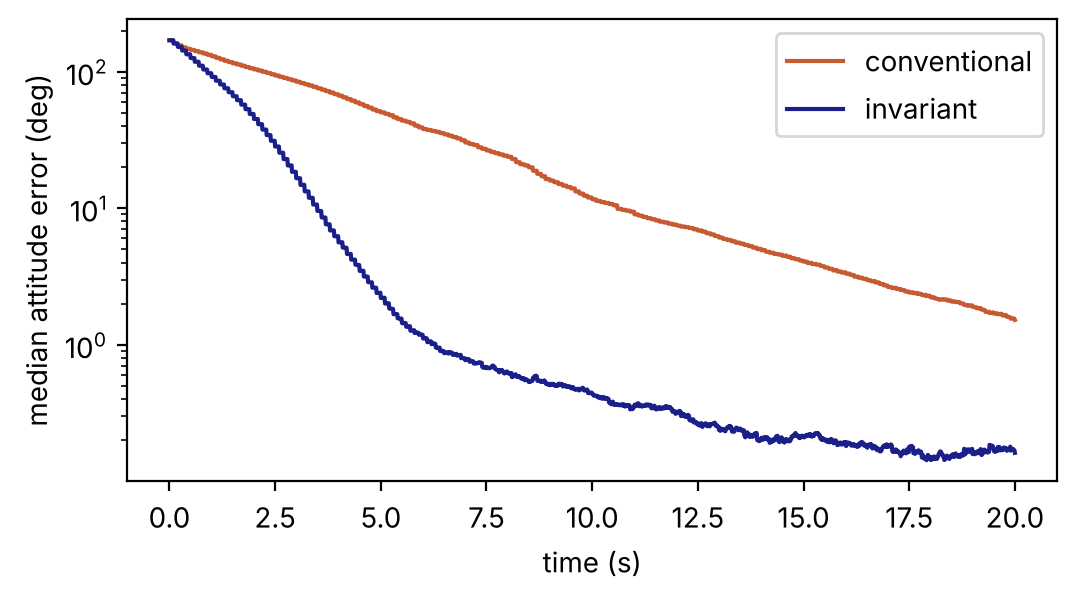

In [7]:
sc = Scenario()
for ang, sv, sx in [(5, 0.2, 0.2), (170, 1.0, 1.0)]:
    r = run_filters(sc, np.random.default_rng(1), 60, ang, sv, sx, fixed_angle=True)
    for name, f in (("invariant", "inv"), ("conventional", "std")):
        a = np.degrees(r[f]["att"])
        print(f"start {ang:3d} deg  {name:12s} median error at 2 s {np.median(a[200]):6.2f} deg, "
              f"at 5 s {np.median(a[500]):6.2f} deg, NEES over the last 5 s {np.mean(r[f]['nees'][-500:]):6.2f}")
plt.figure(figsize=(6, 3))
for f, col in (("std", "#c85a32"), ("inv", "#1b1f8a")):
    plt.semilogy(sc.t, np.median(np.degrees(r[f]["att"]), axis=1), color=col,
                 label={"std": "conventional", "inv": "invariant"}[f])
plt.xlabel("time (s)"); plt.ylabel("median attitude error (deg)"); plt.legend(); plt.show()

## 6. Legs: the contact point joins the group

A simplified demonstration, not the experiment of Hartley et al.: a body with an IMU sways above one fixed
contact. The state is $[R\ v\ x\ x_c] \in \mathrm{SE}_3(3)$ and the leg measures $y = R^\top(x_c - x)$, so
$\tilde y = \hat R\,y - (\hat x_c - \hat x)$ and $C_y = [\,0\ \ I\ \ -I\ \ 0\,]$.

In [8]:
def contact_demo(N=100, seed=11, T=6.0, h=0.005, sig_g=0.002, sig_a=0.04, sig_c=0.05, sig_y=0.01,
                 tilt_deg=20.0, yaw_deg=30.0, sig_v=1.0, sig_x=0.1):
    """A body with an IMU standing on one fixed contact point: a simplified demonstration.

    State [R v x x_c] in SE_3(3), algebra order (v, x, c, R). The measurement is the
    contact point seen from the body, y = R^T (x_c - x) + noise, as leg kinematics gives it.
    Returns time and, per run, tilt error, yaw error, velocity error and position error.
    """
    rng = np.random.default_rng(seed)
    n = int(round(T / h))
    t = np.arange(n + 1) * h
    pos = np.stack([0.10 * np.sin(2.0 * t), 0.06 * np.sin(3.1 * t), 0.90 + 0.04 * np.sin(4.2 * t)], -1)
    vel = np.stack([0.20 * np.cos(2.0 * t), 0.186 * np.cos(3.1 * t), 0.168 * np.cos(4.2 * t)], -1)
    acc = np.stack([-0.40 * np.sin(2.0 * t), -0.5766 * np.sin(3.1 * t), -0.7056 * np.sin(4.2 * t)], -1)
    Rs = exp_so3_b(np.stack([0.15 * np.sin(1.7 * t), 0.20 * np.sin(2.3 * t), 0.10 * np.sin(1.1 * t)], -1))
    Om = np.array([log_so3(Rs[k].T @ Rs[k + 1]) / h for k in range(n)])
    a_s = np.einsum("kji,kj->ki", Rs[:-1], acc[:-1] + G * E3)
    foot = np.array([0.05, -0.12, 0.0])
    Rt, vt, xt = Rs[0], vel[0], pos[0]
    # initial errors, drawn in right-invariant coordinates: tilt, yaw, velocity, positions
    chi0 = np.zeros((N, 12))
    chi0[:, 0:3] = rng.normal(size=(N, 3)) * sig_v
    chi0[:, 3:6] = rng.normal(size=(N, 3)) * sig_x
    chi0[:, 6:9] = rng.normal(size=(N, 3)) * sig_x
    ax = rng.normal(size=(N, 2))
    ax /= np.linalg.norm(ax, axis=1, keepdims=True)
    chi0[:, 9:11] = ax * np.radians(tilt_deg)
    chi0[:, 11] = np.radians(yaw_deg) * rng.choice([-1.0, 1.0], size=N)
    E = exp_so3_b(chi0[:, 9:12])
    J = jl_b(chi0[:, 9:12])
    R = E @ Rt
    v = E @ vt + np.einsum("nij,nj->ni", J, chi0[:, 0:3])
    x = E @ xt + np.einsum("nij,nj->ni", J, chi0[:, 3:6])
    c = E @ foot + np.einsum("nij,nj->ni", J, chi0[:, 6:9])
    Sigma = np.tile(np.diag(np.concatenate([np.full(3, sig_v**2), np.full(6, sig_x**2),
                                        np.full(3, np.radians(max(tilt_deg, yaw_deg))**2)])), (N, 1, 1))
    Sigma_n = np.zeros((12, 12))
    Sigma_n[0:3, 0:3] = np.eye(3) * (sig_a * h) ** 2
    Sigma_n[6:9, 6:9] = np.eye(3) * (sig_c * h) ** 2
    Sigma_n[9:12, 9:12] = np.eye(3) * (sig_g * h) ** 2
    Phi = Phi_right(h, K=3)
    Cy = np.hstack([np.zeros((3, 3)), np.eye(3), -np.eye(3), np.zeros((3, 3))])
    Sigma_y = np.eye(3) * sig_y**2
    I12 = np.eye(12)
    out = dict(tilt=[], yaw=[], vel=[], pos=[], rel=[])

    def record():
        ER = R @ Rt.T
        out["tilt"].append(np.arccos(np.clip(ER[:, 2, 2], -1, 1)))          # angle between E_R e3 and e3
        w = log_so3_b(ER)
        out["yaw"].append(np.abs(w[:, 2]))
        out["vel"].append(np.linalg.norm(np.einsum("nji,nj->ni", R, v) - Rt.T @ vt, axis=1))   # body-frame velocity
        out["pos"].append(np.linalg.norm(x - xt, axis=1))
        out["rel"].append(np.linalg.norm((c - x) - (foot - xt), axis=1))

    record()
    for k in range(n):
        Ad = Ad_b(R, [v, x, c])
        Sigma = Phi @ (Sigma + Ad @ Sigma_n @ np.swapaxes(Ad, 1, 2)) @ Phi.T
        R, v, x = imu_step(R, v, x, Om[k] + rng.normal(size=(N, 3)) * sig_g,
                           a_s[k] + rng.normal(size=(N, 3)) * sig_a, h)
        Rt, vt, xt = imu_step(Rt, vt, xt, Om[k], a_s[k], h)
        y = (foot - xt) @ Rt + rng.normal(size=(N, 3)) * sig_y
        ytilde = np.einsum("nij,nj->ni", R, y) - (c - x)
        Ktilde = np.swapaxes(np.linalg.solve(Cy @ Sigma @ Cy.T + Sigma_y, Cy @ Sigma), 1, 2)
        d = -np.einsum("nij,nj->ni", Ktilde, ytilde)
        E = exp_so3_b(d[:, 9:12])
        J = jl_b(d[:, 9:12])
        v = np.einsum("nij,nj->ni", E, v) + np.einsum("nij,nj->ni", J, d[:, 0:3])
        x = np.einsum("nij,nj->ni", E, x) + np.einsum("nij,nj->ni", J, d[:, 3:6])
        c = np.einsum("nij,nj->ni", E, c) + np.einsum("nij,nj->ni", J, d[:, 6:9])
        R = E @ R
        IK = I12 - Ktilde @ Cy
        Sigma = IK @ Sigma @ np.swapaxes(IK, 1, 2) + Ktilde @ Sigma_y @ np.swapaxes(Ktilde, 1, 2)
        record()
    return t, {key: np.array(val) for key, val in out.items()}, (Phi, Cy)


t, o, (Phi3, Cy3) = contact_demo(N=50)
Ob = np.vstack([Cy3 @ np.linalg.matrix_power(Phi3, k) for k in range(12)])
print("rank of the observability matrix:", np.linalg.matrix_rank(Ob), "of 12")
i1 = int(1.0 / (t[1] - t[0]))
print("median tilt error: start %.1f deg, after 1 s %.2f deg" % tuple(np.degrees([np.median(o["tilt"][0]), np.median(o["tilt"][i1])])))
print("median yaw error at the end: %.1f deg" % np.degrees(np.median(o["yaw"][-1])))

rank of the observability matrix: 8 of 12
median tilt error: start 19.8 deg, after 1 s 0.13 deg
median yaw error at the end: 30.3 deg


## 7. When the state is not a group

The variation-based extended Kalman filter on $S^2$ for the spherical pendulum, next to an extended Kalman
filter on the six numbers $(q, \omega)$. The mapping operator is
$(q, \omega)\oplus s = \big(\exp(\xi^\wedge)q,\ \exp(\xi^\wedge)(\omega + (I - qq^\top)\delta\omega)\big)$
and the covariance is kept in $\ker C$ by the projector $\Pi_C$ (`s2_Pi`).

In [9]:
def pend_f(q, om, l=1.0):
    return np.cross(om, q), -(G / l) * np.cross(q, E3)


def pend_step(q, om, h, l=1.0):
    """RK4 step of the spherical pendulum, put back on the sphere and its tangent plane."""
    def f(z):
        a, b = pend_f(z[:3], z[3:], l)
        return np.concatenate([a, b])
    z = np.concatenate([q, om])
    k1 = f(z)
    k2 = f(z + h / 2 * k1)
    k3 = f(z + h / 2 * k2)
    k4 = f(z + h * k3)
    z = z + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    q = unit(z[:3])
    return q, z[3:] - q * (q @ z[3:])


def expm_series(M):
    """Matrix exponential to third order, for a small step."""
    M2 = M @ M
    return np.eye(M.shape[0]) + M + M2 / 2 + M2 @ M / 6


def s2_A(q, om, l=1.0):
    """Variation-based linearization of the free pendulum: the matrix A of the chapter on linearization."""
    A = np.zeros((6, 6))
    A[:3, :3] = hat(om)
    A[:3, 3:] = np.eye(3) - np.outer(q, q)
    A[3:, :3] = -(G / l) * hat(E3) @ hat(q)
    return A


def s2_C(q, om):
    """Constraint matrix: the linear state s = (xi, delta omega) satisfies C s = 0."""
    C = np.zeros((2, 6))
    C[0, :3] = q
    C[1, :3] = np.cross(q, om)
    C[1, 3:] = q
    return C


def s2_Pi(q, om):
    """Projector onto ker C that keeps xi's tangent part and delta omega's tangent part."""
    Pq = np.eye(3) - np.outer(q, q)
    E = np.zeros((6, 6))
    E[:3, :3] = Pq
    E[3:, 3:] = Pq
    E[3:, :3] = -np.outer(q, np.cross(q, om))
    return E


def s2_oplus(q, om, s):
    """(q, om) (+) s: turn by exp(xi^) and carry the velocity along."""
    Pq = np.eye(3) - np.outer(q, q)
    Rs = expm_so3(Pq @ s[:3])
    return Rs @ q, Rs @ (om + Pq @ s[3:])


def s2_ominus(q2, om2, q1, om1):
    """The variation s with (q1, om1) (+) s = (q2, om2)."""
    ax = np.cross(q1, q2)
    na = np.linalg.norm(ax)
    xi = np.zeros(3) if na < 1e-14 else np.arctan2(na, q1 @ q2) * ax / na
    Rs = expm_so3(xi)
    dom_t = Rs.T @ om2 - om1
    return np.concatenate([xi, dom_t - (om1 @ np.cross(xi, q1)) * q1])


def s2_truth(T=10.0, h=0.01, seed=21, sig_proc=np.sqrt(1e-5)):
    rng = np.random.default_rng(seed)
    n = int(round(T / h))
    q, om = E1.copy(), np.array([0.0, 0.0, 1.2])
    qs, oms = [q], [om]
    for _ in range(n):
        q, om = pend_step(q, om, h)
        Pq = np.eye(3) - np.outer(q, q)
        q, om = s2_oplus(q, om, np.concatenate([Pq @ rng.normal(size=3), Pq @ rng.normal(size=3)]) * sig_proc)
        qs.append(q), oms.append(om)
    return np.arange(n + 1) * h, np.array(qs), np.array(oms)


def s2_filters(truth, seed, sig0=1.0, sig_y=np.sqrt(1e-3), q_proc=1e-5, l=1.0, which=("var", "naive"),
               keep_cov=False):
    """One run of the variation-based extended Kalman filter and of the naive one on the six numbers (q, omega)."""
    t, qs, oms = truth
    h = t[1] - t[0]
    rng = np.random.default_rng(seed)
    Pq = np.eye(3) - np.outer(qs[0], qs[0])
    s0 = np.concatenate([Pq @ rng.normal(size=3), Pq @ rng.normal(size=3)]) * sig0
    q0, om0 = s2_oplus(qs[0], oms[0], s0)
    Sigma_y = np.eye(3) * sig_y**2
    Sigma_n = np.eye(6) * q_proc
    out = {}
    ys = l * qs + rng.normal(size=qs.shape) * sig_y
    if "var" in which:
        q, om = q0.copy(), om0.copy()
        E = s2_Pi(q, om)
        Sigma = E @ (np.eye(6) * sig0**2) @ E.T
        rec = dict(q=[q], om=[om], nees=[], cmax=0.0, cov=[Sigma])
        for k in range(len(t) - 1):
            Ak = expm_series(s2_A(q, om, l) * h)
            q, om = pend_step(q, om, h, l)
            E = s2_Pi(q, om)
            Sigma = E @ (Ak @ Sigma @ Ak.T + Sigma_n) @ E.T
            Cy = np.hstack([-l * hat(q), np.zeros((3, 3))])
            ytilde = l * q - ys[k + 1]
            Ktilde = Sigma @ Cy.T @ np.linalg.inv(Cy @ Sigma @ Cy.T + Sigma_y)
            s = -Ktilde @ ytilde
            rec["cmax"] = max(rec["cmax"], float(np.abs(s2_C(q, om) @ s).max()))
            IK = np.eye(6) - Ktilde @ Cy
            Sigma = IK @ Sigma @ IK.T + Ktilde @ Sigma_y @ Ktilde.T
            Rs = expm_so3(s[:3])
            q, om = s2_oplus(q, om, s)
            Tm = np.zeros((6, 6))
            Tm[:3, :3] = Rs
            Tm[3:, 3:] = Rs
            E = s2_Pi(q, om)
            Sigma = E @ Tm @ Sigma @ Tm.T @ E.T
            rec["cmax"] = max(rec["cmax"], float(np.abs(s2_C(q, om) @ Sigma).max()))
            err = s2_ominus(q, om, qs[k + 1], oms[k + 1])
            rec["nees"].append(float(err @ np.linalg.pinv(Sigma, rcond=1e-10) @ err) / 4)
            rec["q"].append(q), rec["om"].append(om)
            if keep_cov:
                rec["cov"].append(Sigma)
        out["var"] = {key: (np.array(val) if key != "cmax" else val) for key, val in rec.items()}
    if "naive" in which:
        q, om = q0.copy(), om0.copy()
        Sigma = np.eye(6) * sig0**2
        Cy_naive = np.hstack([l * np.eye(3), np.zeros((3, 3))])
        rec = dict(q=[q], om=[om])
        for k in range(len(t) - 1):
            F = np.zeros((6, 6))
            F[:3, :3] = hat(om)
            F[:3, 3:] = -hat(q)
            F[3:, :3] = (G / l) * hat(E3)
            Fk = expm_series(F * h)
            z = np.concatenate([q, om])

            def f(z):
                a, b = pend_f(z[:3], z[3:], l)
                return np.concatenate([a, b])
            k1 = f(z)
            k2 = f(z + h / 2 * k1)
            k3 = f(z + h / 2 * k2)
            k4 = f(z + h * k3)
            z = z + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
            Sigma = Fk @ Sigma @ Fk.T + Sigma_n
            Ktilde = Sigma @ Cy_naive.T @ np.linalg.inv(Cy_naive @ Sigma @ Cy_naive.T + Sigma_y)
            z = z - Ktilde @ (l * z[:3] - ys[k + 1])
            IK = np.eye(6) - Ktilde @ Cy_naive
            Sigma = IK @ Sigma @ IK.T + Ktilde @ Sigma_y @ Ktilde.T
            q, om = z[:3], z[3:]
            rec["q"].append(q), rec["om"].append(om)
        out["naive"] = {key: np.array(val) for key, val in rec.items()}
    return out


truth = s2_truth(T=5.0)
r = s2_filters(truth, 100)
t, qs, oms = truth
for name in ("var", "naive"):
    q = r[name]["q"]
    nrm = np.linalg.norm(q, axis=1)
    ang = np.degrees(np.arccos(np.clip(np.sum(q * qs, axis=1) / nrm, -1, 1)))
    print(f"{name:6s} |q| in [{nrm.min():.4f}, {nrm.max():.4f}], direction error at start {ang[0]:.1f} deg, "
          f"rms after 1 s {np.sqrt(np.mean(ang[100:] ** 2)):.2f} deg")
print("largest |C Sigma| with no constraint update:", r["var"]["cmax"])

var    |q| in [1.0000, 1.0000], direction error at start 47.7 deg, rms after 1 s 0.70 deg
naive  |q| in [0.9816, 1.0377], direction error at start 47.7 deg, rms after 1 s 0.80 deg
largest |C Sigma| with no constraint update: 1.021405182655144e-14


## Starting points for the exercises

- **Compass with large noise.** Call `compass_demo(sig_y=np.radians(60.0))` and look at the wrapped innovations.
- **Group-affine or not.** Add a drag term to the velocity column of `imu_f` and repeat the residual test above.
- **Position fix.** A reading $y = x + n_y$ is $Xd$ with $d = (0, 0, 1)$. Form $\hat X^{-1}[y; 0; 1] - d$ and differentiate it numerically with respect to $\chi$.
- **Gravity leak.** `expm(A_right() * t) @ chi0` with a 1 degree tilt in `chi0[6:]` gives the position part `[3:6]`.
- **Noisy odometry.** `banana()` uses odometry noise and no initial uncertainty. Compare `np.cov(b["chi"][-1].T)` with `b["cov"][-1]`, then halve `sig_V` and `sig_Om`.
- **Two feet.** Extend `contact_demo` with a second contact column and compute the rank again.
- **The pancake.** Check `s2_C(q, om) @ s2_Pi(q, om)` and `s2_Pi @ s2_Pi - s2_Pi` at a random state.

In [10]:
# gravity leak: a tilt error of 1 degree, and the time until it has become 1 m of position error
chi0 = np.concatenate([np.zeros(6), np.radians(1.0) * E1])
for t_ in (1.0, 2.0, 3.42):
    print(t_, "s:", round(np.linalg.norm((expm(A_right() * t_) @ chi0)[3:6]), 3), "m")

# noisy odometry: sample covariance against the linear prediction
bn = banana()
print(np.round(np.diag(np.cov(bn["chi"][-1].T)) / np.diag(bn["cov"][-1]), 2), "ratio of variances (forward, sideways, heading)")

1.0 s: 0.086 m
2.0 s: 0.342 m
3.42 s: 1.001 m
[2.75 1.   0.99] ratio of variances (forward, sideways, heading)
